C:\Users\UserS2025\AppData\Local\Temp\ipykernel_6116\1885177597.py:47: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns


Числовые признаки: 36
Категориальные признаки: 43
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001149 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3202
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 178
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001064 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 181
[LightGBM] [Info] Start training from score 12.016898
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-c

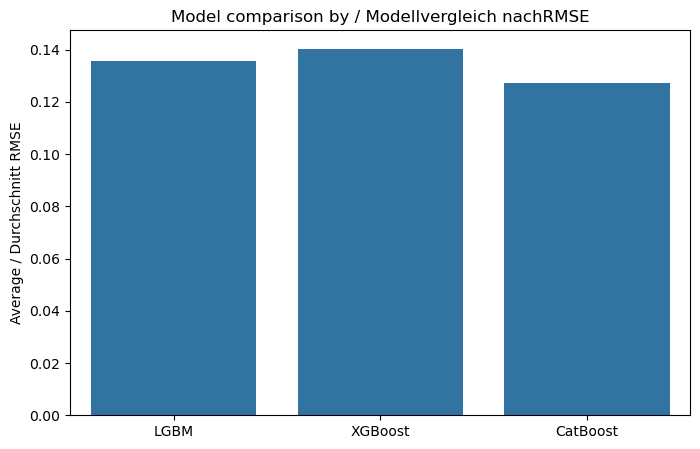

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002079 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3372
[LightGBM] [Info] Number of data points in the train set: 1460, number of used features: 187
[LightGBM] [Info] Start training from score 12.024057
Top-10 features / Top-10 Merkmale LGBM:
        feature  importance
15    GrLivArea        1187
2       LotArea         977
12     1stFlrSF         830
11  TotalBsmtSF         781
26   GarageArea         690
28  OpenPorchSF         674
10    BsmtUnfSF         639
7    MasVnrArea         570
8    BsmtFinSF1         568
1   LotFrontage         561
Top-10 features / Top-10 Merkmale CatBoost:
         feature  importance
45     GrLivArea   17.030963
16   OverallQual   16.876709
37   TotalBsmtSF    4.763418
18     YearBuilt    4.747397
52   KitchenQual    3.595896
33    BsmtF

'\n✅ Особенности этого кода:\n\nПолностью без sklearn Pipeline.\nЛогарифмируем таргет для стабильного RMSE.\nCatBoost работает с категориальными признаками напрямую.\nLGBM/XGBoost используют OHE для категориальных.\nВключён hyperparameter tuning (GridSearchCV) для LGBM и XGBoost.\nЕсть два варианта ансамбля: LGBM+CatBoost и LGBM+CatBoost+XGBoost.\nFeature importance для LGBM и CatBoost.\nГотов к применению на Kaggle.\n\n'

In [ ]:
### ============================================================
### House Prices Prediction
### ============================================================

# Gradient Boosting Models: LightGBM, CatBoost, XGBoost

### Business Context
# Accurate house price estimation is a common regression task in real estate analytics.
# Reliable predictions can support pricing strategies, investment decisions, and market analysis.

### Objective
#Build and compare several gradient boosting models to predict house prices and evaluate them using cross-validation.

### Evaluation Metric
#Root Mean Squared Error (RMSE) on a log-transformed target variable.

# ===============================
# 1️ Importing libraries / Importieren von Bibliotheken
# ===============================
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# 2 Loading data / Daten laden
# ===============================
train = pd.read_csv(r"..\data\raw\train.csv")  # у тебя train уже есть

# ===============================
# 3 Manual data preparation / Manuelle Datenaufbereitung
# ===============================

# Target: applying logarithm for RMSE stability / Ziel: Logarithmus anwenden für stabile RMSE
y = np.log1p(train['SalePrice'])

# Features: removing target, Id, and duplicate log feature / Merkmale: Entfernen von Target, Id und doppeltem Log-Feature
X = train.drop(columns=['SalePrice', 'Id', 'SalePrice_log'], errors='ignore')

# Numerical and categorical features / Numerische und kategoriale Merkmale
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print(f"Числовые признаки: {len(num_cols)}")
print(f"Категориальные признаки: {len(cat_cols)}")

# 3.1 Numerical features processing / 3.1 Verarbeitung numerischer Merkmale
X_num = X[num_cols].copy()
for col in X_num.columns:
    # Replacing NaN with median / Ersetzen von NaN durch Median
    X_num[col] = X_num[col].fillna(X_num[col].median())
    # Scaling (optional) / Skalierung (optional) масштабируем (опционально)
    X_num[col] = (X_num[col] - X_num[col].mean()) / X_num[col].std()

# 3.2 Categorical features processing / 3.2 Verarbeitung kategorialer Merkmale
X_cat = X[cat_cols].copy()
for col in X_cat.columns:
    # Replacing NaN with the most frequent value / Ersetzen von NaN durch den häufigsten Wert
    X_cat[col] = X_cat[col].fillna(X_cat[col].mode()[0])

# CatBoost can handle NaN directly, so we can leave them as is / CatBoost kann NaN direkt verarbeiten, daher können wir sie so belassen
# For LGBM and XGBoost, apply OneHotEncoding / Für LGBM und XGBoost OneHotEncoding anwenden
X_cat_ohe = pd.get_dummies(X_cat, drop_first=False)

# 3.3 Combining numerical and categorical features for LGBM/XGB / 3.3 Numerische und kategoriale Merkmale für LGBM/XGB zusammenführen
X_processed = pd.concat([X_num, X_cat_ohe], axis=1)

# ===============================
# 4️ Cross-Validation for models / Kreuzvalidierung für Modelle
# ===============================
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

# --- 4.1 LGBM ---
rmse_scores_lgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    lgb_model = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
    lgb_model.fit(X_train, y_train)
    y_pred = lgb_model.predict(X_val)
    rmse_scores_lgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['LGBM'] = np.mean(rmse_scores_lgb)
print(f"LGBM: Average / Durchschnittlicher RMSE = {results['LGBM']:.4f}")

# --- 4.2 XGBoost ---
rmse_scores_xgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train)
    y_pred = xgb_model.predict(X_val)
    rmse_scores_xgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['XGBoost'] = np.mean(rmse_scores_xgb)
print(f"XGBoost: Average / Durchschnittlicher RMSE = {results['XGBoost']:.4f}")

# --- 4.3 CatBoost ---
rmse_scores_cb = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # CatBoost: Replacing NaN in categorical features with "Missing" / Ersetzen von NaN in kategorialen Merkmalen durch "Missing"
    for col in cat_cols:
        X_train[col] = X_train[col].fillna("Missing")
        X_val[col] = X_val[col].fillna("Missing")

    cb_model = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
    cb_model.fit(X_train, y_train, cat_features=cat_cols.tolist())
    y_pred = cb_model.predict(X_val)
    rmse_scores_cb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['CatBoost'] = np.mean(rmse_scores_cb)
print(f"CatBoost: Average / Durchschnittlicher RMSE = {results['CatBoost']:.4f}")

# ===============================
# 5 Model comparison / Modellvergleich
# ===============================
plt.figure(figsize=(8,5))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.ylabel("Average / Durchschnitt RMSE")
plt.title("Model comparison by / Modellvergleich nachRMSE")
plt.show()

# ===============================
# 6️ Feature Importance
# ===============================
# LGBM
lgb_model_final = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
lgb_model_final.fit(X_processed, y)
lgb_feat_imp = pd.DataFrame({
    'feature': X_processed.columns,
    'importance': lgb_model_final.feature_importances_
}).sort_values(by='importance', ascending=False)
print("Top-10 features / Top-10 Merkmale LGBM:")
print(lgb_feat_imp.head(10))

# CatBoost
X_cb_final = X.copy()
for col in cat_cols:
    X_cb_final[col] = X_cb_final[col].fillna("Missing")
cb_model_final = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
cb_model_final.fit(X_cb_final, y, cat_features=cat_cols.tolist())
cb_feat_imp = pd.DataFrame({
    'feature': X_cb_final.columns,
    'importance': cb_model_final.get_feature_importance()
}).sort_values(by='importance', ascending=False)
print("Top-10 features / Top-10 Merkmale CatBoost:")
print(cb_feat_imp.head(10))

# ===============================
# 7️ Hyperparameter Tuning (z.B.)
# ===============================
# LGBM
lgb_grid = {
    'n_estimators': [500, 1000],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 50]
}
lgb_search = GridSearchCV(LGBMRegressor(random_state=42), lgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
lgb_search.fit(X_processed, y)
print("Best parameters / Beste Parameter LGBM:", lgb_search.best_params_)

# CatBoost
cb_model_tune = CatBoostRegressor(random_state=42, verbose=0)
cb_grid = {'depth': [4,6], 'learning_rate':[0.03,0.05], 'iterations':[500,1000]}
# GridSearchCV с CatBoost требует обёртку или кастомную функцию, для простоты можно пробовать вручную

# XGBoost
xgb_grid = {
    'n_estimators':[500,1000],
    'learning_rate':[0.05,0.1],
    'max_depth':[3,5]
}
xgb_search = GridSearchCV(XGBRegressor(random_state=42, verbosity=0), xgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
xgb_search.fit(X_processed, y)
print("Best parameters / Beste Parameter XGBoost:", xgb_search.best_params_)

# ===============================
# 8️ Ensemble
# ===============================
# 8.1 LGBM + CatBoost (простое усреднение предсказаний)
lgb_preds = lgb_model_final.predict(X_processed)
cb_preds = cb_model_final.predict(X_cb_final)
ensemble_lgb_cb = (lgb_preds + cb_preds) / 2
rmse_ensemble_lgb_cb = np.sqrt(mean_squared_error(y, ensemble_lgb_cb))
print(f"RMSE of LGBM + CatBoost ensemble / RMSE des LGBM + CatBoost Ensembles: {rmse_ensemble_lgb_cb:.4f}")

# 8.2 LGBM + CatBoost + XGBoost
xgb_model_final = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
xgb_model_final.fit(X_processed, y)
xgb_preds = xgb_model_final.predict(X_processed)

ensemble_all = (lgb_preds + cb_preds + xgb_preds) / 3
rmse_ensemble_all = np.sqrt(mean_squared_error(y, ensemble_all))
print(f"RMSE Ensemble LGBM + CatBoost + XGBoost: {rmse_ensemble_all:.4f}")

'''
✅ Особенности этого кода:

Полностью без sklearn Pipeline.
Логарифмируем таргет для стабильного RMSE.
CatBoost работает с категориальными признаками напрямую.
LGBM/XGBoost используют OHE для категориальных.
Включён hyperparameter tuning (GridSearchCV) для LGBM и XGBoost.
Есть два варианта ансамбля: LGBM+CatBoost и LGBM+CatBoost+XGBoost.
Feature importance для LGBM и CatBoost.
Готов к применению на Kaggle.

'''


In [ ]:
# ===============================
# 9️ Final Kaggle-ready prediction set / Finaler Kaggle-bereiter Vorhersagesatz
# ===============================

import pandas as pd
import numpy as np
from catboost import Pool

# 9.0 test.csv
test = pd.read_csv(r"..\data\raw\test.csv")

# 9.1 Test set preprocessing for LGBM/XGBoost / Testdatensatz-Vorverarbeitung für LGBM/XGBoost
X_test_num = test[num_cols].copy()
for col in X_test_num.columns:
    # Using median and statistics from the training set / Verwendung von Median und Statistiken aus dem Trainingssatz
    X_test_num[col] = X_test_num[col].fillna(X_num[col].median())
    X_test_num[col] = (X_test_num[col] - X_num[col].mean()) / X_num[col].std()

X_test_cat = test[cat_cols].copy()
for col in X_test_cat.columns:
    X_test_cat[col] = X_test_cat[col].fillna(X_cat[col].mode()[0])

X_test_cat_ohe = pd.get_dummies(X_test_cat, drop_first=False)
X_test_processed = pd.concat([X_test_num, X_test_cat_ohe], axis=1)

# Aligning columns with the training set (if there are differences in OHE) / Spalten mit dem Trainingssatz angleichen (falls Unterschiede im OHE vorhanden sind)
X_test_processed = X_test_processed.reindex(columns=X_processed.columns, fill_value=0)

# 9.2 Test set preprocessing for CatBoost / Testdatensatz-Vorverarbeitung für CatBoost
X_test_cb = test.copy()
for col in cat_cols:
    X_test_cb[col] = X_test_cb[col].astype(str).fillna("Missing")

# Creating a Pool for CatBoost to handle categorical features correctly / Erstellen eines Pools für CatBoost, um kategoriale Merkmale korrekt zu verarbeiten
test_pool = Pool(data=X_test_cb, cat_features=cat_cols.tolist())

# 9.3Ensemble predictions / Ensemble-Vorhersagen LGBM + CatBoost + XGBoost
final_preds_log = (
    lgb_model_final.predict(X_test_processed) +
    cb_model_final.predict(test_pool) +
    xgb_model_final.predict(X_test_processed)
) / 3

# Inverse transformation / Inverse Transformation log1p
final_preds = np.expm1(final_preds_log)

# 9.4 Creation / Erstellung DataFrame for Kaggle
test_ids = test['Id'] if 'Id' in test.columns else test.index

submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': final_preds
})

# 9.5 Saving CSV for Kaggle / CSV für Kaggle speichern
submission.to_csv('submission_kaggle.csv', index=False)
print("Файл 'submission_kaggle.csv' успешно создан!")


Файл 'submission_kaggle.csv' успешно создан!


In [5]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Словарь для хранения RMSE
rmse_dict = {}

# 1. Каждая модель отдельно
rmse_dict['LGBM'] = np.sqrt(mean_squared_error(y, lgb_preds))
rmse_dict['CatBoost'] = np.sqrt(mean_squared_error(y, cb_preds))
rmse_dict['XGBoost'] = np.sqrt(mean_squared_error(y, xgb_preds))

# 2. Все пары
rmse_dict['LGBM+CatBoost'] = np.sqrt(mean_squared_error(y, (lgb_preds + cb_preds)/2))
rmse_dict['LGBM+XGBoost'] = np.sqrt(mean_squared_error(y, (lgb_preds + xgb_preds)/2))
rmse_dict['CatBoost+XGBoost'] = np.sqrt(mean_squared_error(y, (cb_preds + xgb_preds)/2))

# 3. Все три вместе
rmse_dict['LGBM+CatBoost+XGBoost'] = np.sqrt(mean_squared_error(y, (lgb_preds + cb_preds + xgb_preds)/3))

# Печать результатов
for combo, rmse in rmse_dict.items():
    print(f"{combo}: RMSE = {rmse:.4f}")

LGBM: RMSE = 0.0192
CatBoost: RMSE = 0.0807
XGBoost: RMSE = 0.0153
LGBM+CatBoost: RMSE = 0.0471
LGBM+XGBoost: RMSE = 0.0154
CatBoost+XGBoost: RMSE = 0.0456
LGBM+CatBoost+XGBoost: RMSE = 0.0350
